# CSE 485 / 488: Deep Learning — Final Project
## Milestone 1, Task 1.2: GoogLeNet (Inception v1) CNN Encoder
### Standalone Kaggle Notebook (Loads Dataset Directly from GitHub)

This notebook automatically **clones the private GitHub repository** to fetch the preprocessed dataset from Task 1.1:
- **5,989 Cleaned Original Photos** (`src/data/original/images`)
- **10,084 Augmented Photos** (`src/data/processed/augmented/images`)
- **Metadata Files** (`metadata.csv` with `original_id` for grouped validation splitting)

---
### 🔑 Kaggle Setup & GitHub Token
Because the repository is private, you need your own GitHub Personal Access Token (PAT) with read access (`repo` scope):
1. In your Kaggle notebook, open the top menu: **Add-ons → Secrets**.
2. Add a secret with Label: `GITHUB_TOKEN` and Value: your GitHub token (starts with `ghp_...`).
3. Set Accelerator to **GPU T4 x1** and toggle **Internet On**.
4. Click **Run All**.

In [1]:
# Install dependencies and verify GPU
!pip install -q datasets scikit-learn matplotlib

import torch
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available:  {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Active GPU:      {torch.cuda.get_device_name(0)}")

PyTorch version: 2.11.0+cu128
CUDA available:  True
Active GPU:      Tesla T4


In [2]:
# Standard imports and output path configuration
import os
import csv
import math
import time
import json
import random
import shlex
import itertools
import subprocess
from pathlib import Path
from collections import defaultdict

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from datasets import load_dataset
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = Path("/kaggle/working/outputs" if os.path.exists("/kaggle") else "./outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Device:  {DEVICE}")
print(f"Outputs: {OUTPUT_DIR}")

Device:  cuda
Outputs: /kaggle/working/outputs


## 1. Clone GitHub Repository & Load Dataset
We clone `omarsaher/image-classfication-and-caption` into `/tmp/repo` so that all original and augmented images are directly accessible.

In [3]:
REPO = "omarsaher/image-classfication-and-caption"
BRANCH = "main"  # Branch containing the dataset
WORKDIR = Path("/tmp/repo" if os.path.exists("/kaggle") else ".")

# Check if dataset already exists locally (e.g. running from repo root)
orig_meta = WORKDIR / "src/data/original/metadata/metadata.csv"
orig_imgs = WORKDIR / "src/data/original/images"

if not (orig_meta.exists() and orig_imgs.exists()):
    # Retrieve GitHub Token (from Kaggle Secrets or secure prompt)
    GITHUB_TOKEN = None
    try:
        from kaggle_secrets import UserSecretsClient
        GITHUB_TOKEN = UserSecretsClient().get_secret("GITHUB_TOKEN").strip()
        print("Successfully loaded GITHUB_TOKEN from Kaggle Secrets.")
    except Exception:
        try:
            from google.colab import userdata
            GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")
        except Exception:
            GITHUB_TOKEN = os.environ.get("GITHUB_TOKEN")

    if not GITHUB_TOKEN:
        import getpass
        print("\n--- GitHub Authentication ---")
        print("The repository is private. As a collaborator on this repo, enter your GitHub Personal Access Token (PAT):")
        GITHUB_TOKEN = getpass.getpass("GITHUB_TOKEN: ").strip()

    print(f"\nCloning repository '{REPO}' (branch: {BRANCH}) to {WORKDIR}...")
    clone_url = f"https://{GITHUB_TOKEN}@github.com/{REPO}.git"
    res = subprocess.run(
        ["git", "clone", "--depth", "1", "-b", BRANCH, clone_url, str(WORKDIR)],
        capture_output=True, text=True
    )
    if res.returncode != 0:
        clean_err = res.stderr.replace(GITHUB_TOKEN, "***") if GITHUB_TOKEN else res.stderr
        raise RuntimeError(f"Git clone failed: {clean_err}\nPlease check your GITHUB_TOKEN access rights.")

    # Remove credentials from git remote for security
    subprocess.run(["git", "-C", str(WORKDIR), "remote", "set-url", "origin", f"https://github.com/{REPO}.git"], check=True)
    print("Git clone completed successfully!")

# Verify data files
orig_meta = WORKDIR / "src/data/original/metadata/metadata.csv"
orig_imgs = WORKDIR / "src/data/original/images"
aug_meta  = WORKDIR / "src/data/processed/augmented/metadata/metadata.csv"
aug_imgs  = WORKDIR / "src/data/processed/augmented/images"

assert orig_meta.exists() and orig_imgs.exists(), f"Error: original data missing at {orig_imgs}"
print(f"Original data directory:  {orig_imgs}")
print(f"Augmented data directory: {aug_imgs if aug_imgs.exists() else 'Not found'}")

Successfully loaded GITHUB_TOKEN from Kaggle Secrets.

Cloning repository 'omarsaher/image-classfication-and-caption' (branch: main) to /tmp/repo...
Git clone completed successfully!
Original data directory:  /tmp/repo/src/data/original/images
Augmented data directory: /tmp/repo/src/data/processed/augmented/images


In [4]:
# Read Task 1.1 metadata files and perform grouped train/val split by original_id
def read_metadata(images_dir, metadata_csv):
    images_dir = Path(images_dir)
    with open(metadata_csv, "r", encoding="utf-8") as f:
        return [
            {
                "path": images_dir / r["filename"],
                "label": int(r["label"]),
                "class_name": r["class_name"],
                "original_id": r["original_id"],
                "image_type": r["image_type"],
            }
            for r in csv.DictReader(f)
            if (images_dir / r["filename"]).exists()
        ]

orig_records = read_metadata(orig_imgs, orig_meta)
aug_records  = read_metadata(aug_imgs, aug_meta) if (aug_imgs.exists() and aug_meta.exists()) else []

print(f"Loaded from GitHub repo:")
print(f"  - Original Cleaned Images:  {len(orig_records)}")
print(f"  - Augmented Copies:         {len(aug_records)}")

class_names_map = {r["label"]: r["class_name"] for r in orig_records}
CLASS_NAMES = [class_names_map[i] for i in sorted(class_names_map)]
NUM_CLASSES = len(CLASS_NAMES)
print(f"  - Number of Bird Classes:   {NUM_CLASSES}")

# Grouped Split by original_id: exactly as implemented in src/data/splits.py
def make_grouped_split(original_records, val_per_class=5, seed=42):
    ids_by_label = defaultdict(list)
    for record in original_records:
        ids_by_label[record["label"]].append(record["original_id"])
    rng = random.Random(seed)
    val_ids = []
    for label in sorted(ids_by_label):
        ids = sorted(ids_by_label[label], key=str)
        val_ids.extend(rng.sample(ids, min(val_per_class, len(ids))))
    return set(val_ids)

def split_records(original_records, augmented_records, val_ids, use_augmented=False):
    train = [r for r in original_records if r["original_id"] not in val_ids]
    if use_augmented:
        train += [r for r in augmented_records if r["original_id"] not in val_ids]
    val = [r for r in original_records if r["original_id"] in val_ids]
    return train, val

val_ids = make_grouped_split(orig_records, val_per_class=5, seed=42)
train_orig, val_recs = split_records(orig_records, aug_records, val_ids, use_augmented=False)
train_aug, _         = split_records(orig_records, aug_records, val_ids, use_augmented=True)

print(f"\nDataset Splits:")
print(f"  - Validation Set (held out originals): {len(val_recs)} images")
print(f"  - Run A Training (Originals only):     {len(train_orig)} images")
print(f"  - Run B Training (Originals + Aug):     {len(train_aug)} images")

Loaded from GitHub repo:
  - Original Cleaned Images:  5989
  - Augmented Copies:         10084
  - Number of Bird Classes:   200

Dataset Splits:
  - Validation Set (held out originals): 1000 images
  - Run A Training (Originals only):     4989 images
  - Run B Training (Originals + Aug):     13398 images


In [5]:
# PyTorch Dataset & DataLoaders
class RecordDataset(Dataset):
    def __init__(self, records, transform=None):
        self.records = records
        self.transform = transform

    def __len__(self):
        return len(self.records)

    def __getitem__(self, index):
        rec = self.records[index]
        image = Image.open(rec["path"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, rec["label"]

class HFCUBTestDataset(Dataset):
    def __init__(self, transform=None):
        self.ds = load_dataset("Multimodal-Fatima/CUB_test", split="test")
        self.class_names = self.ds.features["label"].names
        self.transform = transform

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, index):
        row = self.ds[index]
        image = row["image"].convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, row["label"]

NORM_MEAN = [0.485, 0.456, 0.406]
NORM_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.35, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=NORM_MEAN, std=NORM_STD),
])

def build_loaders(use_augmented=False, batch_size=64, num_workers=2):
    train_records = train_aug if use_augmented else train_orig
    train_ds = RecordDataset(train_records, transform=train_transform)
    val_ds   = RecordDataset(val_recs, transform=eval_transform)
    test_ds  = HFCUBTestDataset(transform=eval_transform)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, pin_memory=torch.cuda.is_available(), drop_last=True)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, pin_memory=torch.cuda.is_available())
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False,
                              num_workers=num_workers, pin_memory=torch.cuda.is_available())
    return train_loader, val_loader, test_loader, test_ds

train_loader, val_loader, test_loader, test_ds = build_loaders(use_augmented=False)
print("DataLoaders successfully built.")

README.md:   0%|          | 0.00/7.15k [00:00<?, ?B/s]

data/test-00000-of-00002-32b23bf2f7b849a(…): reconstructing file:   0%|          |  0.00B /  279MB            

data/test-00000-of-00002-32b23bf2f7b849a(…): downloading bytes:           |  0.00B            

data/test-00001-of-00002-3cd446126954ca1(…): reconstructing file:   0%|          |  0.00B /  286MB            

data/test-00001-of-00002-3cd446126954ca1(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/5794 [00:00<?, ? examples/s]

DataLoaders successfully built.


## 2. GoogLeNet (Inception v1) Architecture from Scratch
Implements the Inception architecture (Szegedy et al., 2015) with BatchNorm replacing LRN for training stability.
Supports `width_mult` scaling (0.5 for fast training ~1.8M params; 1.0 for standard ~6.0M params).
Returns multi-scale feature maps `c1`..`c5` for future colorization/captioning and defines `gradcam_layer` on Stage 5.

In [6]:
def _scaled(ch: int, width_mult: float) -> int:
    return max(8, int(round(ch * width_mult / 8)) * 8)

def _conv_bn_relu(in_ch: int, out_ch: int, kernel_size: int, stride: int = 1, padding: int = 0) -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size, stride=stride, padding=padding, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )

class InceptionBlock(nn.Module):
    def __init__(self, in_ch: int, out_1x1: int, reduce_3x3: int, out_3x3: int,
                 reduce_5x5: int, out_5x5: int, out_pool: int):
        super().__init__()
        self.branch1 = _conv_bn_relu(in_ch, out_1x1, 1)
        self.branch2 = nn.Sequential(
            _conv_bn_relu(in_ch, reduce_3x3, 1),
            _conv_bn_relu(reduce_3x3, out_3x3, 3, padding=1),
        )
        self.branch3 = nn.Sequential(
            _conv_bn_relu(in_ch, reduce_5x5, 1),
            _conv_bn_relu(reduce_5x5, out_5x5, 5, padding=2),
        )
        self.branch4 = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            _conv_bn_relu(in_ch, out_pool, 1),
        )
        self.out_channels = out_1x1 + out_3x3 + out_5x5 + out_pool

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat([self.branch1(x), self.branch2(x), self.branch3(x), self.branch4(x)], dim=1)

class GoogLeNetEncoder(nn.Module):
    _INCEPTION_CFG = {
        "3a": ( 64,  96, 128, 16,  32,  32),
        "3b": (128, 128, 192, 32,  96,  64),
        "4a": (192,  96, 208, 16,  48,  64),
        "4b": (160, 112, 224, 24,  64,  64),
        "4c": (128, 128, 256, 24,  64,  64),
        "4d": (112, 144, 288, 32,  64,  64),
        "4e": (256, 160, 320, 32, 128, 128),
        "5a": (256, 160, 320, 32, 128, 128),
        "5b": (384, 192, 384, 48, 128, 128),
    }

    def __init__(self, width_mult: float = 1.0, in_channels: int = 3):
        super().__init__()
        def s(ch): return _scaled(ch, width_mult)
        def inception(name, in_ch):
            cfg = self._INCEPTION_CFG[name]
            return InceptionBlock(in_ch, s(cfg[0]), s(cfg[1]), s(cfg[2]), s(cfg[3]), s(cfg[4]), s(cfg[5]))

        c1_ch = s(64)
        self.stem = _conv_bn_relu(in_channels, c1_ch, 7, stride=2, padding=3)

        c2_mid, c2_ch = s(64), s(192)
        self.stage2 = nn.Sequential(
            nn.MaxPool2d(3, stride=2, padding=1),
            _conv_bn_relu(c1_ch, c2_mid, 1),
            _conv_bn_relu(c2_mid, c2_ch, 3, padding=1),
        )

        inc3a = inception("3a", c2_ch)
        inc3b = inception("3b", inc3a.out_channels)
        self.stage3 = nn.Sequential(nn.MaxPool2d(3, stride=2, padding=1), inc3a, inc3b)
        c3_ch = inc3b.out_channels

        inc4a = inception("4a", c3_ch)
        inc4b = inception("4b", inc4a.out_channels)
        inc4c = inception("4c", inc4b.out_channels)
        inc4d = inception("4d", inc4c.out_channels)
        inc4e = inception("4e", inc4d.out_channels)
        self.stage4 = nn.Sequential(nn.MaxPool2d(3, stride=2, padding=1), inc4a, inc4b, inc4c, inc4d, inc4e)
        c4_ch = inc4e.out_channels

        inc5a = inception("5a", c4_ch)
        inc5b = inception("5b", inc5a.out_channels)
        self.stage5 = nn.Sequential(nn.MaxPool2d(3, stride=2, padding=1), inc5a, inc5b)
        c5_ch = inc5b.out_channels

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_channels = [c1_ch, c2_ch, c3_ch, c4_ch, c5_ch]
        self.feature_dim = c5_ch
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    @property
    def gradcam_layer(self) -> nn.Module:
        return self.stage5

    def forward_features(self, x: torch.Tensor) -> dict:
        c1 = self.stem(x)
        c2 = self.stage2(c1)
        c3 = self.stage3(c2)
        c4 = self.stage4(c3)
        c5 = self.stage5(c4)
        pooled = self.pool(c5).flatten(1)
        return {"c1": c1, "c2": c2, "c3": c3, "c4": c4, "c5": c5, "pooled": pooled}

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.forward_features(x)["pooled"]

class GoogLeNetClassifier(nn.Module):
    def __init__(self, num_classes=200, width_mult=1.0, dropout=0.4):
        super().__init__()
        self.encoder = GoogLeNetEncoder(width_mult=width_mult)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(self.encoder.feature_dim, num_classes)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.encoder(x))

    @property
    def gradcam_layer(self):
        return self.encoder.gradcam_layer

for wm in [0.5, 1.0]:
    m = GoogLeNetClassifier(num_classes=NUM_CLASSES, width_mult=wm)
    print(f"GoogLeNet (width_mult={wm}): {sum(p.numel() for p in m.parameters() if p.requires_grad):,} trainable parameters")

GoogLeNet (width_mult=0.5): 1,612,264 trainable parameters
GoogLeNet (width_mult=1.0): 6,185,832 trainable parameters


## 3. Training Engine

In [7]:
def build_optimizer(model, lr=1e-3, weight_decay=0.05):
    decay, no_decay = [], []
    for param in model.parameters():
        if not param.requires_grad:
            continue
        (no_decay if param.ndim <= 1 else decay).append(param)
    return torch.optim.AdamW([
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ], lr=lr)

def warmup_cosine(total_steps, warmup_steps):
    def factor(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * min(1.0, progress)))
    return factor

class Trainer:
    def __init__(self, model, train_loader, val_loader, lr=1e-3, weight_decay=0.05,
                 epochs=40, warmup_epochs=4, patience=15, label_smoothing=0.1,
                 checkpoint_name="googlenet_best.pt", max_batches=None):
        self.model = model.to(DEVICE)
        self.train_loader = train_loader
        self.val_loader = val_loader
        self.epochs = epochs
        self.patience = patience
        self.max_batches = max_batches
        self.checkpoint_path = OUTPUT_DIR / checkpoint_name

        steps_per_epoch = len(train_loader) if max_batches is None else min(len(train_loader), max_batches)
        self.criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
        self.optimizer = build_optimizer(model, lr=lr, weight_decay=weight_decay)
        self.scheduler = torch.optim.lr_scheduler.LambdaLR(
            self.optimizer,
            warmup_cosine(epochs * steps_per_epoch, warmup_epochs * steps_per_epoch)
        )
        self.use_amp = (DEVICE.type == "cuda")
        self.scaler = torch.amp.GradScaler("cuda", enabled=self.use_amp)

    def train_epoch(self, epoch):
        self.model.train()
        total_loss, correct, total = 0.0, 0, 0
        for step, (images, labels) in enumerate(self.train_loader):
            if self.max_batches and step >= self.max_batches:
                break
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast("cuda", enabled=self.use_amp):
                logits = self.model(images)
                loss = self.criterion(logits, labels)

            self.optimizer.zero_grad(set_to_none=True)
            self.scaler.scale(loss).backward()
            self.scaler.step(self.optimizer)
            self.scaler.update()
            self.scheduler.step()

            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
        return total_loss / total, correct / total

    @torch.no_grad()
    def evaluate(self, loader):
        self.model.eval()
        total_loss, correct, total = 0.0, 0, 0
        for step, (images, labels) in enumerate(loader):
            if self.max_batches and step >= self.max_batches:
                break
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            with torch.amp.autocast("cuda", enabled=self.use_amp):
                logits = self.model(images)
                loss = self.criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(1) == labels).sum().item()
            total += labels.size(0)
        return total_loss / total, correct / total

    def fit(self, verbose=True):
        history = []
        best_val_acc = -1.0
        best_epoch = -1
        no_improve = 0

        for epoch in range(1, self.epochs + 1):
            t0 = time.time()
            train_loss, train_acc = self.train_epoch(epoch)
            val_loss, val_acc = self.evaluate(self.val_loader)
            elapsed = time.time() - t0

            history.append({
                "epoch": epoch,
                "train_loss": train_loss,
                "train_acc": train_acc,
                "val_loss": val_loss,
                "val_acc": val_acc,
                "lr": self.optimizer.param_groups[0]["lr"],
                "time_sec": elapsed,
            })

            if verbose:
                print(f"Epoch {epoch:2d}/{self.epochs} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | "
                      f"Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} | LR: {self.optimizer.param_groups[0]['lr']:.6f} ({elapsed:.1f}s)")

            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_epoch = epoch
                no_improve = 0
                torch.save({
                    "model_state": self.model.state_dict(),
                    "best_val_acc": best_val_acc,
                    "epoch": epoch,
                    "class_names": CLASS_NAMES,
                    "norm_mean": NORM_MEAN,
                    "norm_std": NORM_STD,
                }, self.checkpoint_path)
            else:
                no_improve += 1
                if no_improve >= self.patience:
                    if verbose:
                        print(f"Early stopping triggered at epoch {epoch} (patience={self.patience})")
                    break

        return {"history": history, "best_val_acc": best_val_acc, "best_epoch": best_epoch, "checkpoint": str(self.checkpoint_path)}

## 4. Smoke Test

In [8]:
print("Running smoke test (1 epoch, 5 batches)...")
smoke_model = GoogLeNetClassifier(num_classes=NUM_CLASSES, width_mult=0.5)
smoke_trainer = Trainer(
    smoke_model, train_loader, val_loader,
    lr=1e-3, epochs=1, warmup_epochs=0, patience=1,
    checkpoint_name="smoke_test.pt", max_batches=5
)
smoke_res = smoke_trainer.fit(verbose=True)
print("Smoke test passed successfully!")

Running smoke test (1 epoch, 5 batches)...
Epoch  1/1 | Train Loss: 5.4071 Acc: 0.0000 | Val Loss: 5.3892 Acc: 0.0156 | LR: 0.000000 (6.7s)
Smoke test passed successfully!


## 5. Hyperparameter Tuning: Grid Search vs. Random Search
Required in Milestone 1: We tune learning rate, weight decay, width multiplier, and dropout.

In [9]:
def run_hyperparameter_search(trials_budget=6, epochs_per_trial=6):
    print("=" * 60)
    print(f"Hyperparameter Tuning: Grid Search vs. Random Search ({trials_budget} trials, {epochs_per_trial} epochs)")
    print("=" * 60)
    
    # 1. Grid Search
    grid_space = list(itertools.product([0.0005, 0.001], [0.01, 0.05], [0.5, 1.0]))[:trials_budget]
    grid_results = []
    print("\n--- Grid Search ---")
    for i, (lr, wd, wm) in enumerate(grid_space):
        print(f"[Grid {i+1}/{len(grid_space)}] lr={lr}, weight_decay={wd}, width_mult={wm}")
        t0 = time.time()
        m = GoogLeNetClassifier(num_classes=NUM_CLASSES, width_mult=wm, dropout=0.3)
        tr = Trainer(m, train_loader, val_loader, lr=lr, weight_decay=wd,
                     epochs=epochs_per_trial, warmup_epochs=1, patience=epochs_per_trial,
                     checkpoint_name=f"grid_trial_{i}.pt")
        res = tr.fit(verbose=False)
        dur = time.time() - t0
        print(f"   Best Val Acc: {res['best_val_acc']:.4f} in {dur/60:.2f} min")
        grid_results.append({
            "trial": i + 1, "method": "Grid", "lr": lr, "weight_decay": wd,
            "width_mult": wm, "dropout": 0.3, "best_val_acc": res["best_val_acc"], "time_sec": dur
        })

    # 2. Random Search
    rng = random.Random(123)
    random_results = []
    print("\n--- Random Search ---")
    for i in range(trials_budget):
        lr = math.exp(rng.uniform(math.log(0.0001), math.log(0.005)))
        wd = math.exp(rng.uniform(math.log(0.001), math.log(0.1)))
        wm = rng.choice([0.5, 1.0])
        drop = rng.uniform(0.2, 0.5)
        print(f"[Random {i+1}/{trials_budget}] lr={lr:.5f}, weight_decay={wd:.5f}, width_mult={wm}, dropout={drop:.2f}")
        t0 = time.time()
        m = GoogLeNetClassifier(num_classes=NUM_CLASSES, width_mult=wm, dropout=drop)
        tr = Trainer(m, train_loader, val_loader, lr=lr, weight_decay=wd,
                     epochs=epochs_per_trial, warmup_epochs=1, patience=epochs_per_trial,
                     checkpoint_name=f"random_trial_{i}.pt")
        res = tr.fit(verbose=False)
        dur = time.time() - t0
        print(f"   Best Val Acc: {res['best_val_acc']:.4f} in {dur/60:.2f} min")
        random_results.append({
            "trial": i + 1, "method": "Random", "lr": lr, "weight_decay": wd,
            "width_mult": wm, "dropout": drop, "best_val_acc": res["best_val_acc"], "time_sec": dur
        })
    return grid_results, random_results

grid_results, random_results = run_hyperparameter_search(trials_budget=6, epochs_per_trial=6)

Hyperparameter Tuning: Grid Search vs. Random Search (6 trials, 6 epochs)

--- Grid Search ---
[Grid 1/6] lr=0.0005, weight_decay=0.01, width_mult=0.5
   Best Val Acc: 0.0750 in 1.84 min
[Grid 2/6] lr=0.0005, weight_decay=0.01, width_mult=1.0
   Best Val Acc: 0.1690 in 1.92 min
[Grid 3/6] lr=0.0005, weight_decay=0.05, width_mult=0.5
   Best Val Acc: 0.0870 in 1.83 min
[Grid 4/6] lr=0.0005, weight_decay=0.05, width_mult=1.0
   Best Val Acc: 0.1610 in 1.91 min
[Grid 5/6] lr=0.001, weight_decay=0.01, width_mult=0.5
   Best Val Acc: 0.1250 in 1.80 min
[Grid 6/6] lr=0.001, weight_decay=0.01, width_mult=1.0


/tmp/ipykernel_22/386482925.py:59: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  self.scheduler.step()


   Best Val Acc: 0.2040 in 1.90 min

--- Random Search ---
[Random 1/6] lr=0.00012, weight_decay=0.00149, width_mult=1.0, dropout=0.28
   Best Val Acc: 0.0580 in 1.88 min
[Random 2/6] lr=0.00266, weight_decay=0.05619, width_mult=1.0, dropout=0.36
   Best Val Acc: 0.1760 in 1.90 min
[Random 3/6] lr=0.00037, weight_decay=0.05060, width_mult=0.5, dropout=0.24
   Best Val Acc: 0.0540 in 1.77 min
[Random 4/6] lr=0.00090, weight_decay=0.02532, width_mult=0.5, dropout=0.20
   Best Val Acc: 0.1050 in 1.80 min
[Random 5/6] lr=0.00055, weight_decay=0.00150, width_mult=1.0, dropout=0.22
   Best Val Acc: 0.1770 in 1.91 min
[Random 6/6] lr=0.00034, weight_decay=0.00788, width_mult=0.5, dropout=0.23
   Best Val Acc: 0.0580 in 1.81 min


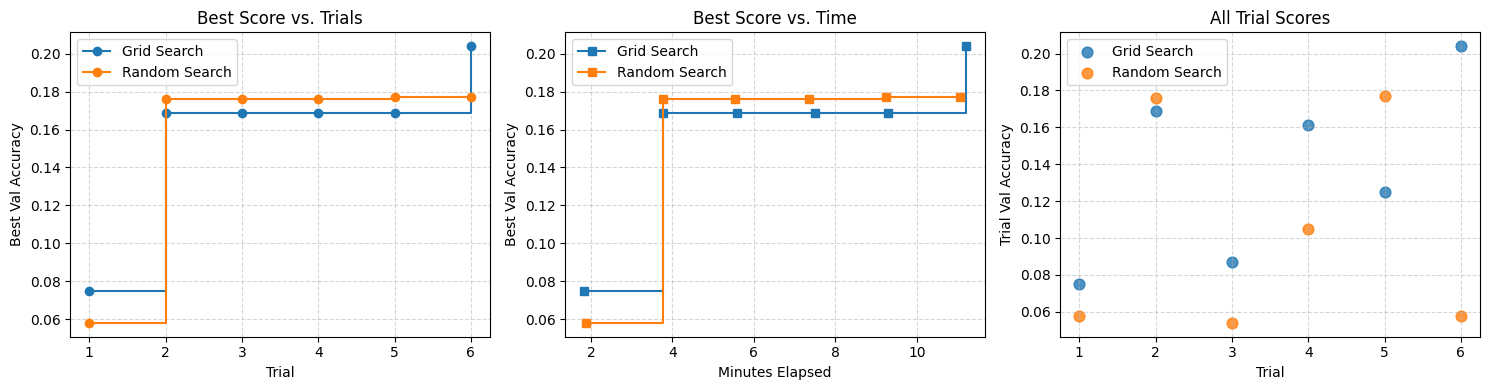

WINNING TRIAL (Grid): Val Acc = 0.2040
Parameters: LR=0.00100, Weight Decay=0.01000, Width Mult=1.0, Dropout=0.30


In [10]:
# Plot Tuning Comparison
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4))

for name, res in [("Grid Search", grid_results), ("Random Search", random_results)]:
    trials = [r["trial"] for r in res]
    accs = [r["best_val_acc"] for r in res]
    best_so_far = [max(accs[:i+1]) for i in range(len(accs))]
    mins = np.cumsum([r["time_sec"] / 60 for r in res])
    
    ax1.step(trials, best_so_far, where="post", label=name, marker="o")
    ax2.step(mins, best_so_far, where="post", label=name, marker="s")
    ax3.scatter(trials, accs, label=name, s=60, alpha=0.8)

ax1.set(xlabel="Trial", ylabel="Best Val Accuracy", title="Best Score vs. Trials")
ax2.set(xlabel="Minutes Elapsed", ylabel="Best Val Accuracy", title="Best Score vs. Time")
ax3.set(xlabel="Trial", ylabel="Trial Val Accuracy", title="All Trial Scores")
for ax in (ax1, ax2, ax3):
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "tuning_comparison.png", dpi=150)
plt.show()

best_trial = max(grid_results + random_results, key=lambda x: x["best_val_acc"])
print("=" * 60)
print(f"WINNING TRIAL ({best_trial['method']}): Val Acc = {best_trial['best_val_acc']:.4f}")
print(f"Parameters: LR={best_trial['lr']:.5f}, Weight Decay={best_trial['weight_decay']:.5f}, "
      f"Width Mult={best_trial['width_mult']}, Dropout={best_trial['dropout']:.2f}")
print("=" * 60)

## 6. Full Training Experiments: Run A (Originals) vs. Run B (Originals + Augmented)
We train two models with the best hyperparameters:
- **Run A**: Trained on the 4,989 original training photos only.
- **Run B**: Trained on the 4,989 originals + 8,407 Task 1.1 offline augmented copies (~13,396 images).
Then we compare their training dynamics and overfitting gaps.

In [11]:
FINAL_EPOCHS = 35
print(f"--- Starting Run A (Originals Only) for {FINAL_EPOCHS} epochs ---")
loader_A, val_loader, test_loader, test_ds = build_loaders(use_augmented=False)

model_A = GoogLeNetClassifier(num_classes=NUM_CLASSES, width_mult=best_trial["width_mult"], dropout=best_trial["dropout"])
trainer_A = Trainer(
    model_A, loader_A, val_loader,
    lr=best_trial["lr"], weight_decay=best_trial["weight_decay"],
    epochs=FINAL_EPOCHS, warmup_epochs=3, patience=12,
    checkpoint_name="googlenet_A_originals.pt"
)
res_A = trainer_A.fit(verbose=True)

print(f"\n--- Starting Run B (Originals + Augmented) for {FINAL_EPOCHS} epochs ---")
loader_B, _, _, _ = build_loaders(use_augmented=True)
model_B = GoogLeNetClassifier(num_classes=NUM_CLASSES, width_mult=best_trial["width_mult"], dropout=best_trial["dropout"])
trainer_B = Trainer(
    model_B, loader_B, val_loader,
    lr=best_trial["lr"], weight_decay=best_trial["weight_decay"],
    epochs=FINAL_EPOCHS, warmup_epochs=3, patience=12,
    checkpoint_name="googlenet_B_augmented.pt"
)
res_B = trainer_B.fit(verbose=True)

--- Starting Run A (Originals Only) for 35 epochs ---
Epoch  1/35 | Train Loss: 5.3036 Acc: 0.0112 | Val Loss: 5.1924 Acc: 0.0190 | LR: 0.000338 (18.9s)
Epoch  2/35 | Train Loss: 5.0235 Acc: 0.0266 | Val Loss: 4.9789 Acc: 0.0410 | LR: 0.000671 (19.1s)
Epoch  3/35 | Train Loss: 4.7361 Acc: 0.0497 | Val Loss: 4.7163 Acc: 0.0530 | LR: 0.001000 (19.7s)
Epoch  4/35 | Train Loss: 4.5053 Acc: 0.0690 | Val Loss: 4.4465 Acc: 0.0770 | LR: 0.000998 (19.2s)
Epoch  5/35 | Train Loss: 4.2498 Acc: 0.1090 | Val Loss: 4.2621 Acc: 0.1040 | LR: 0.000990 (19.4s)
Epoch  6/35 | Train Loss: 4.0601 Acc: 0.1331 | Val Loss: 4.1000 Acc: 0.1450 | LR: 0.000978 (18.7s)
Epoch  7/35 | Train Loss: 3.8760 Acc: 0.1721 | Val Loss: 4.0566 Acc: 0.1480 | LR: 0.000962 (19.5s)
Epoch  8/35 | Train Loss: 3.7225 Acc: 0.1952 | Val Loss: 3.8188 Acc: 0.1800 | LR: 0.000941 (19.3s)
Epoch  9/35 | Train Loss: 3.5365 Acc: 0.2309 | Val Loss: 3.8449 Acc: 0.1930 | LR: 0.000916 (19.2s)
Epoch 10/35 | Train Loss: 3.3602 Acc: 0.2833 | Val Loss

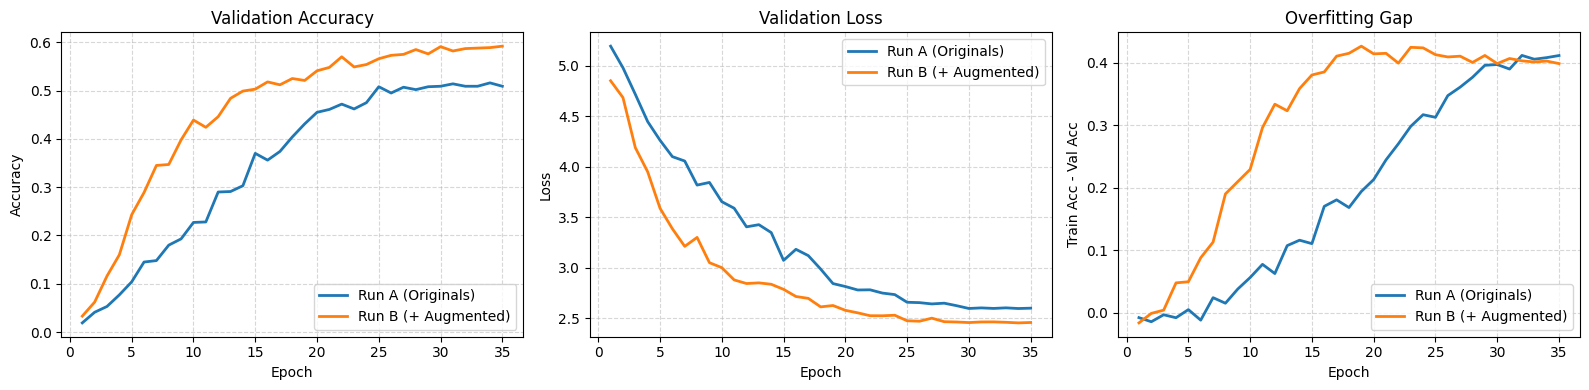

Selected Best Checkpoint: /kaggle/working/outputs/googlenet_B_augmented.pt (Val Acc: 0.5920)


In [12]:
# Compare Run A vs Run B: Validation Accuracy, Loss, and Overfitting Gap
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4))

for name, res in [("Run A (Originals)", res_A), ("Run B (+ Augmented)", res_B)]:
    hist = res["history"]
    eps = [h["epoch"] for h in hist]
    val_accs = [h["val_acc"] for h in hist]
    val_losses = [h["val_loss"] for h in hist]
    gaps = [h["train_acc"] - h["val_acc"] for h in hist]
    
    ax1.plot(eps, val_accs, label=name, lw=2)
    ax2.plot(eps, val_losses, label=name, lw=2)
    ax3.plot(eps, gaps, label=name, lw=2)

ax1.set(xlabel="Epoch", ylabel="Accuracy", title="Validation Accuracy")
ax2.set(xlabel="Epoch", ylabel="Loss", title="Validation Loss")
ax3.set(xlabel="Epoch", ylabel="Train Acc - Val Acc", title="Overfitting Gap")
for ax in (ax1, ax2, ax3):
    ax.legend()
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "run_comparison_A_vs_B.png", dpi=150)
plt.show()

best_overall_res = res_B if res_B["best_val_acc"] > res_A["best_val_acc"] else res_A
print(f"Selected Best Checkpoint: {best_overall_res['checkpoint']} (Val Acc: {best_overall_res['best_val_acc']:.4f})")

## 7. Comprehensive Evaluation on CUB-200 Test Split (5,794 images)
Computing Top-1 Accuracy, Macro-Precision, Macro-Recall, Macro-F1, Confusion Matrix, and Confusions.

Evaluating test set...

TEST ACCURACY:   59.53%
MACRO PRECISION: 0.5949
MACRO RECALL:    0.5957
MACRO F1-SCORE:  0.5895


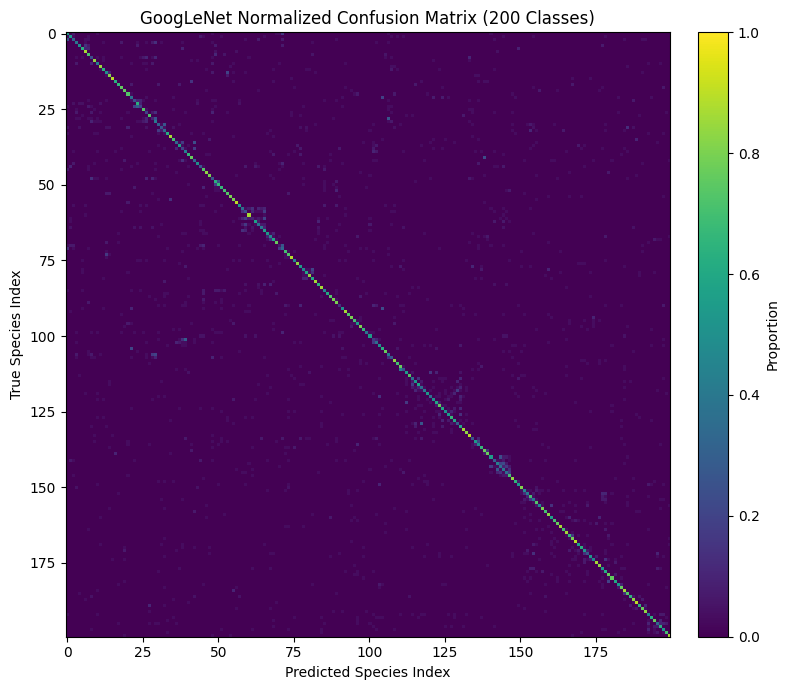

In [13]:
# Load selected best checkpoint and evaluate on test set
ckpt = torch.load(best_overall_res["checkpoint"], map_location=DEVICE)
eval_model = GoogLeNetClassifier(num_classes=NUM_CLASSES, width_mult=best_trial["width_mult"], dropout=best_trial["dropout"]).to(DEVICE)
eval_model.load_state_dict(ckpt["model_state"])
eval_model.eval()

@torch.no_grad()
def evaluate_dataset(model, loader):
    y_true, y_pred, y_conf = [], [], []
    for images, labels in loader:
        images = images.to(DEVICE)
        probs = torch.softmax(model(images), dim=1)
        conf, preds = probs.max(dim=1)
        y_true.extend(labels.numpy())
        y_pred.extend(preds.cpu().numpy())
        y_conf.extend(conf.cpu().numpy())
    return np.array(y_true), np.array(y_pred), np.array(y_conf)

print("Evaluating test set...")
y_true, y_pred, y_conf = evaluate_dataset(eval_model, test_loader)

acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

print("\n" + "=" * 40)
print(f"TEST ACCURACY:   {acc*100:.2f}%")
print(f"MACRO PRECISION: {prec:.4f}")
print(f"MACRO RECALL:    {rec:.4f}")
print(f"MACRO F1-SCORE:  {f1:.4f}")
print("=" * 40)

# Save evaluation JSON
report = {
    "test_accuracy": float(acc),
    "macro_precision": float(prec),
    "macro_recall": float(rec),
    "macro_f1": float(f1),
    "best_epoch": best_overall_res["best_epoch"],
    "best_val_accuracy": best_overall_res["best_val_acc"],
}
with open(OUTPUT_DIR / "metrics.json", "w") as f:
    json.dump(report, f, indent=2)

# Plot Confusion Matrix
plt.figure(figsize=(8, 7))
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
plt.imshow(cm_norm, cmap="viridis", vmin=0, vmax=1)
plt.title("GoogLeNet Normalized Confusion Matrix (200 Classes)")
plt.xlabel("Predicted Species Index")
plt.ylabel("True Species Index")
plt.colorbar(fraction=0.046, pad=0.04, label="Proportion")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## 8. Model Explainability with Grad-CAM

Plotting Grad-CAM for Correct Predictions:


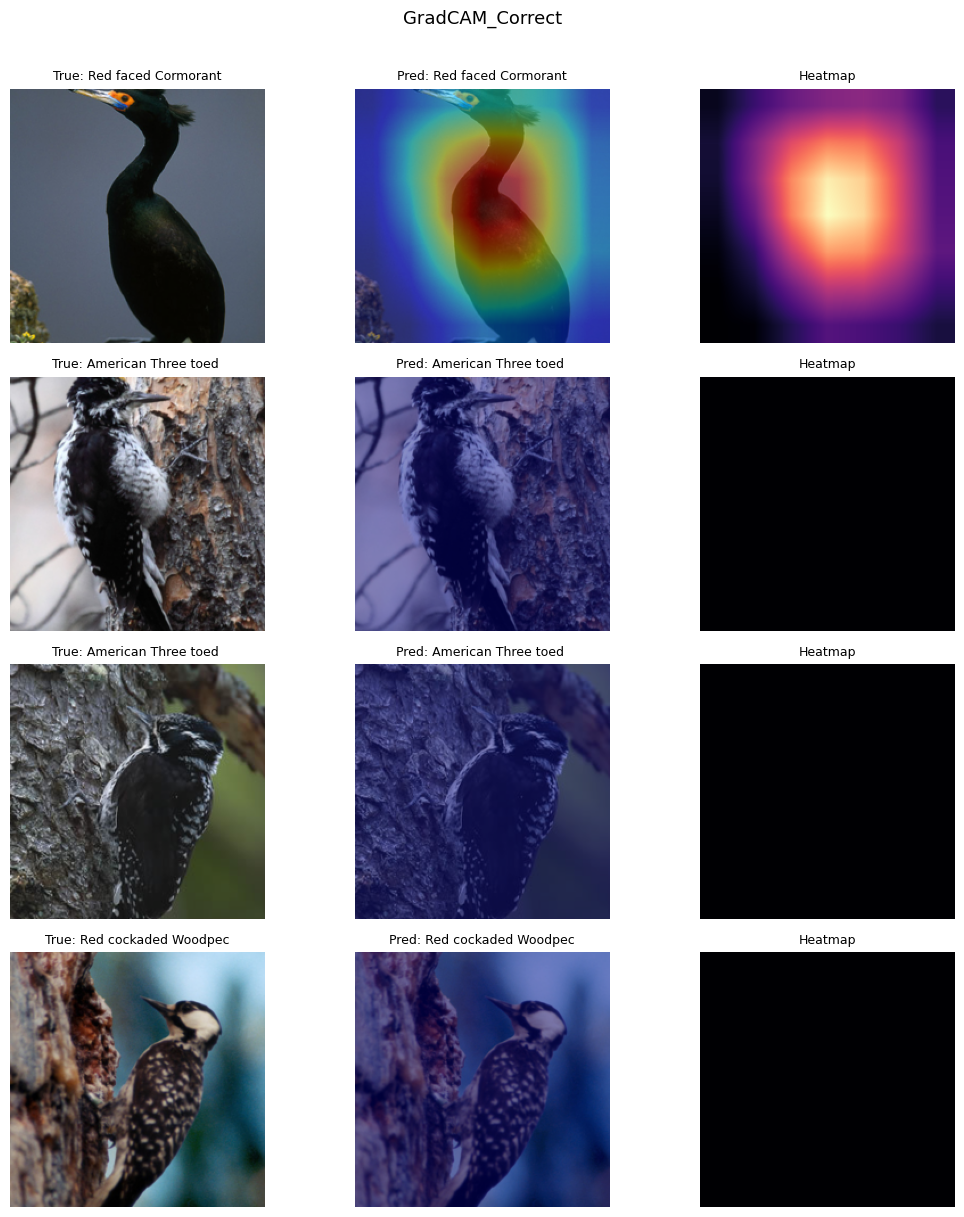

Plotting Grad-CAM for Wrong Predictions:


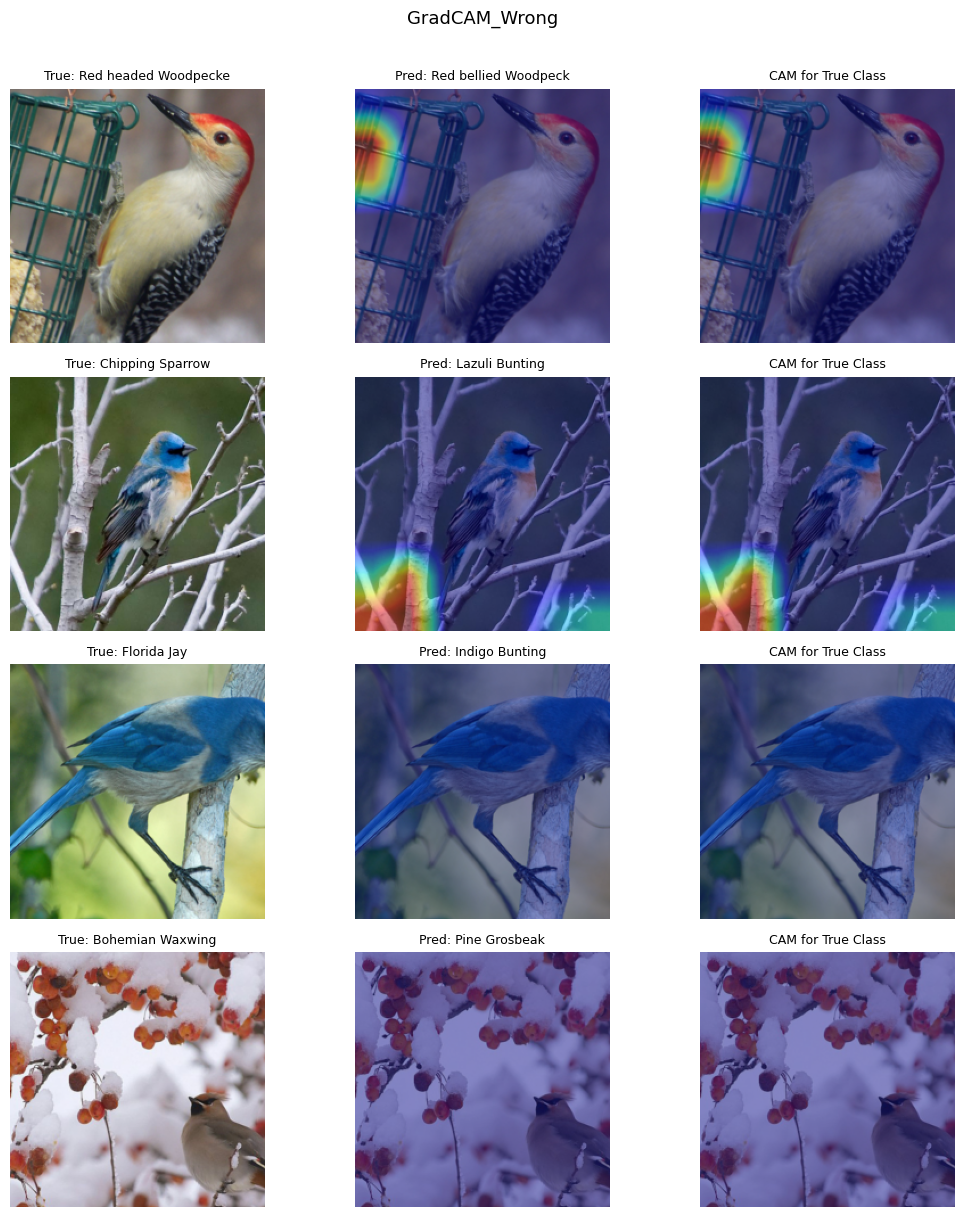

In [14]:
class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self._h_fwd = target_layer.register_forward_hook(self._hook_fwd)
        self._h_bwd = None

    def _hook_fwd(self, module, inp, out):
        self.activations = out
        if self._h_bwd is None:
            self._h_bwd = out.register_hook(self._hook_bwd_fn)

    def _hook_bwd_fn(self, grad):
        self.gradients = grad

    def __call__(self, x, class_idx=None):
        self.model.eval()
        self.model.zero_grad()
        with torch.enable_grad():
            logits = self.model(x)
            pred = logits.argmax(dim=1)
            target = pred if class_idx is None else class_idx
            score = logits.gather(1, target.view(-1, 1)).sum()
            score.backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, pred.item()

def denormalize(t):
    img = t.clone().detach().cpu().numpy().transpose(1, 2, 0)
    return (img * np.array(NORM_STD) + np.array(NORM_MEAN)).clip(0, 1)

cam_gen = GradCAM(eval_model, eval_model.gradcam_layer)

def plot_cam_grid(indices, title="GradCAM"):
    n = len(indices)
    fig, axes = plt.subplots(n, 3, figsize=(11, 3.0 * n))
    if n == 1:
        axes = [axes]
    
    for r, idx in enumerate(indices):
        tensor, true_y = test_ds[idx]
        x = tensor.unsqueeze(0).to(DEVICE)
        cam_map, pred_y = cam_gen(x)
        orig = denormalize(tensor)
        
        # 1. Original
        axes[r][0].imshow(orig)
        axes[r][0].set_title(f"True: {CLASS_NAMES[true_y][:20]}", fontsize=9)
        axes[r][0].axis("off")
        
        # 2. Predicted heatmap overlay
        axes[r][1].imshow(orig)
        axes[r][1].imshow(cam_map, cmap="jet", alpha=0.45)
        axes[r][1].set_title(f"Pred: {CLASS_NAMES[pred_y][:20]}", fontsize=9)
        axes[r][1].axis("off")
        
        # 3. CAM for True class if mistake, else raw heatmap
        if pred_y != true_y:
            true_cam, _ = cam_gen(x, class_idx=torch.tensor([true_y], device=DEVICE))
            axes[r][2].imshow(orig)
            axes[r][2].imshow(true_cam, cmap="jet", alpha=0.45)
            axes[r][2].set_title("CAM for True Class", fontsize=9)
        else:
            axes[r][2].imshow(cam_map, cmap="magma")
            axes[r][2].set_title("Heatmap", fontsize=9)
        axes[r][2].axis("off")
        
    plt.suptitle(title, fontsize=13, y=1.01)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f"{title.lower()}.png", dpi=150, bbox_inches="tight")
    plt.show()

correct_idx = np.where(y_true == y_pred)[0]
wrong_idx = np.where(y_true != y_pred)[0]

top_correct = correct_idx[np.argsort(-y_conf[correct_idx])][:4]
top_wrong = wrong_idx[np.argsort(-y_conf[wrong_idx])][:4]

print("Plotting Grad-CAM for Correct Predictions:")
plot_cam_grid(top_correct, title="GradCAM_Correct")

print("Plotting Grad-CAM for Wrong Predictions:")
plot_cam_grid(top_wrong, title="GradCAM_Wrong")

## 9. Interactive Inference Demo

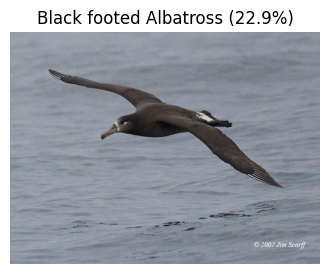

Top-5 Predictions:
  1. Black footed Albatross              : 22.94%
  2. Sooty Albatross                     : 13.71%
  3. Laysan Albatross                    :  3.14%
  4. Caspian Tern                        :  2.93%
  5. Northern Fulmar                     :  2.19%


In [15]:
def predict_bird(image_obj, topk=5):
    eval_model.eval()
    img_pil = image_obj.convert("RGB") if isinstance(image_obj, Image.Image) else Image.open(image_obj).convert("RGB")
    tensor = eval_transform(img_pil).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probs = torch.softmax(eval_model(tensor), dim=1)[0]
        vals, inds = torch.topk(probs, topk)
    
    plt.figure(figsize=(4, 4))
    plt.imshow(img_pil)
    plt.axis("off")
    plt.title(f"{CLASS_NAMES[inds[0]]} ({vals[0]*100:.1f}%)")
    plt.show()
    
    print(f"Top-{topk} Predictions:")
    for i, (v, idx) in enumerate(zip(vals, inds), 1):
        print(f"  {i}. {CLASS_NAMES[idx]:<35} : {v.item()*100:5.2f}%")

# Predict sample bird
sample_bird = test_ds.ds[25]["image"]
predict_bird(sample_bird, topk=5)

## 10. Package & Download Artifacts

In [16]:
import shutil

zip_dest = "/kaggle/working/googlenet_task1_2_results" if os.path.exists("/kaggle") else "./googlenet_task1_2_results"
archive_path = shutil.make_archive(zip_dest, "zip", OUTPUT_DIR)
print(f"Successfully created results archive: {archive_path}")
print(f"Archive size: {os.path.getsize(archive_path) / (1024*1024):.2f} MB\n")
print("Contents of outputs folder:")
for f in sorted(OUTPUT_DIR.iterdir()):
    print(f"  - {f.name} ({f.stat().st_size / 1024:.1f} KB)")

Successfully created results archive: /kaggle/working/googlenet_task1_2_results.zip
Archive size: 219.80 MB

Contents of outputs folder:
  - confusion_matrix.png (64.1 KB)
  - googlenet_A_originals.pt (24353.2 KB)
  - googlenet_B_augmented.pt (24353.2 KB)
  - gradcam_correct.png (1624.7 KB)
  - gradcam_wrong.png (1653.6 KB)
  - grid_trial_0.pt (6455.4 KB)
  - grid_trial_1.pt (24350.2 KB)
  - grid_trial_2.pt (6455.4 KB)
  - grid_trial_3.pt (24350.2 KB)
  - grid_trial_4.pt (6455.4 KB)
  - grid_trial_5.pt (24350.2 KB)
  - metrics.json (0.2 KB)
  - random_trial_0.pt (24350.8 KB)
  - random_trial_1.pt (24350.8 KB)
  - random_trial_2.pt (6456.1 KB)
  - random_trial_3.pt (6456.1 KB)
  - random_trial_4.pt (24350.8 KB)
  - random_trial_5.pt (6456.1 KB)
  - run_comparison_A_vs_B.png (148.4 KB)
  - smoke_test.pt (6454.7 KB)
  - tuning_comparison.png (82.6 KB)
